In [6]:
import os, glob, json, re
from urllib.parse import urlparse

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [7]:
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)

In [14]:
DATA_DIR = "../TT Dataset/TT Dataset/data"   # 9 run berfault + file label
NOFAULT_DIR = "../work/raw_nofault"          # 3 run normal (hasil ekstrak)
SHIFT = 8 * 3600                          # selisih waktu spans/logs vs metrics (dibuktikan di Langkah A4)

In [15]:
fault_runs = sorted(d for d in glob.glob(f"{DATA_DIR}/TT.2*") if os.path.isdir(d))
nofault_runs = sorted(os.path.dirname(p)
                      for p in glob.glob(f"{NOFAULT_DIR}/**/spans.json", recursive=True))

print("Run berfault :", len(fault_runs))
print("Run normal   :", len(nofault_runs))

RUN = fault_runs[0]            # run yang dipakai untuk eksplorasi detail
print("\nIsi satu run:", RUN)
for f in sorted(os.listdir(RUN)):
    p = os.path.join(RUN, f)
    if os.path.isdir(p):
        print(f"  {f}/  ({len(os.listdir(p))} file)")
    else:
        print(f"  {f}  ({os.path.getsize(p)/1e6:.1f} MB)")

Run berfault : 9
Run normal   : 3

Isi satu run: ../TT Dataset/TT Dataset/data/TT.2022-04-17T212101D2022-04-17T230842
  logs.json  (1.7 MB)
  metrics/  (27 file)
  spans.json  (42.8 MB)


In [18]:
rows = []
for r in fault_runs:
    name = os.path.basename(r)                                   # TT.2022-04-17T212101D...
    label = json.load(open(f"{DATA_DIR}/TT.fault-{name[3:]}.json"))
    for i, f in enumerate(label["faults"]):
        service = f["name"].replace("dockercomposemanifests_", "").rsplit("_", 1)[0]
        rows.append(dict(run=name[3:20], urutan=i, service=service, fault=f["fault"],
                         start=f["start"], durasi=f["duration"],
                         run_start=label["start"], run_end=label["end"]))
faults = pd.DataFrame(rows)

print("Jumlah fault:", len(faults))
print(faults.fault.value_counts(), "\n")
print("Service berbeda yang di-fault:", faults.service.nunique())
faults.head(9)

Jumlah fault: 81
fault
cpu_load         27
network_delay    27
network_loss     27
Name: count, dtype: int64 

Service berbeda yang di-fault: 27


,run,urutan,service,fault,start,durasi,run_start,run_end
0,2022-04-17T212101,0,ts-food-service,cpu_load,1.650173e+09,600,1.650173e+09,1.650179e+09
1,2022-04-17T212101,1,ts-food-service,network_delay,1.650174e+09,600,1.650173e+09,1.650179e+09
2,2022-04-17T212101,2,ts-food-service,network_loss,1.650174e+09,600,1.650173e+09,1.650179e+09
3,2022-04-17T212101,3,ts-travel-service,cpu_load,1.650175e+09,600,1.650173e+09,1.650179e+09
4,2022-04-17T212101,4,ts-travel-service,network_delay,1.650176e+09,600,1.650173e+09,1.650179e+09
5,2022-04-17T212101,5,ts-travel-service,network_loss,1.650176e+09,600,1.650173e+09,1.650179e+09
6,2022-04-17T212101,6,ts-contacts-service,cpu_load,1.650177e+09,600,1.650173e+09,1.650179e+09
7,2022-04-17T212101,7,ts-contacts-service,network_delay,1.650178e+09,600,1.650173e+09,1.650179e+09
8,2022-04-17T212101,8,ts-contacts-service,network_loss,1.650179e+09,600,1.650173e+09,1.650179e+09


In [19]:
# Apakah setiap service mendapat ketiga jenis fault?
print(pd.crosstab(faults.service, faults.fault).describe().loc[["min", "max"]], "\n")

# Durasi fault dan jeda antar fault
faults["jeda_ke_berikut"] = faults.groupby("run").start.shift(-1) - (faults.start + faults.durasi)
print("Durasi fault (detik):", faults.durasi.unique())
print("Jeda antar fault (detik):", faults.jeda_ke_berikut.describe()[["min", "mean", "max"]].round(1).to_dict())

lama_run = faults.groupby("run").first().eval("(run_end - run_start) / 3600")
print("Lama satu run (jam):", lama_run.round(3).unique())

fault  cpu_load  network_delay  network_loss
min         1.0            1.0           1.0
max         1.0            1.0           1.0 

Durasi fault (detik): [600]
Jeda antar fault (detik): {'min': 114.1, 'mean': 118.2, 'max': 124.5}
Lama satu run (jam): [1.795]


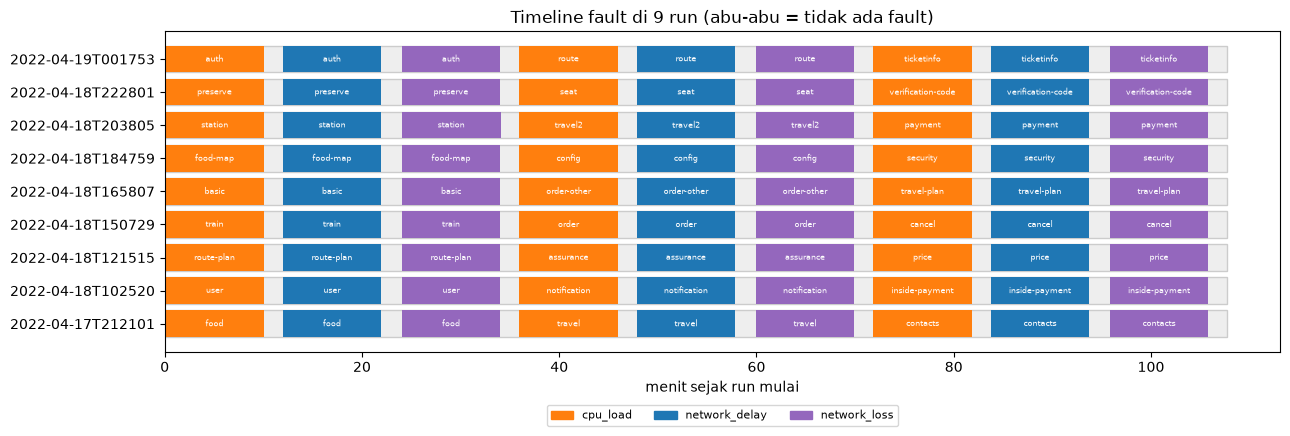

In [22]:
# Visualisasi Timeline

warna = {"cpu_load": "tab:orange", "network_delay": "tab:blue", "network_loss": "tab:purple"}
fig, ax = plt.subplots(figsize=(13, 4.5))
for y, (run, g) in enumerate(faults.groupby("run")):
    t0 = g.run_start.iloc[0]
    ax.barh(y, (g.run_end.iloc[0] - t0) / 60, left=0, color="#eee", edgecolor="#ccc")
    for _, f in g.iterrows():
        ax.barh(y, f.durasi / 60, left=(f.start - t0) / 60, color=warna[f.fault])
        ax.text((f.start - t0 + f.durasi / 2) / 60, y, re.sub(r"^ts-|-service$", "", f.service),
                ha="center", va="center", fontsize=6, color="white")
ax.set_yticks(range(faults.run.nunique()), sorted(faults.run.unique()))
ax.set_xlabel("menit sejak run mulai")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in warna.values()], labels=list(warna),
          loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=3, fontsize=8)
ax.set_title("Timeline fault di 9 run (abu-abu = tidak ada fault)")
plt.tight_layout(); plt.show()

## Metrics

In [23]:
m = pd.read_csv(f"{RUN}/metrics/ts-food-service.csv")
print(m.shape)
print(m.head(3), "\n")
print("Selisih timestamp berturut-turut:", m.timestamp.diff().value_counts().to_dict())
print("Jumlah NaN:", int(m.isna().sum().sum()))
m.describe().T[["mean", "std", "min", "max"]]

(6461, 8)
    timestamp  cpu_usage_system  cpu_usage_total  cpu_usage_user  memory_usage  memory_working_set  rx_bytes  tx_bytes
0  1650172861              0.01         0.017287            0.01      0.004667            0.004644     496.0      70.0
1  1650172862              0.01         0.017287            0.01      0.004667            0.004644     496.0      70.0
2  1650172863              0.08         1.167646            1.10      0.005344            0.005315     385.0     190.0 

Selisih timestamp berturut-turut: {1.0: 6460}
Jumlah NaN: 0


,mean,std,min,max
timestamp,1.650176e+09,1865.274377,1.650173e+09,1.650179e+09
cpu_usage_system,7.956973e-03,0.024964,0.000000e+00,2.700000e-01
cpu_usage_total,4.320923e+00,14.049958,3.322955e-04,8.191048e+01
cpu_usage_user,4.300971e+00,13.988512,0.000000e+00,8.174000e+01
memory_usage,4.674140e-03,0.000030,4.664719e-03,5.344480e-03
memory_working_set,4.650029e-03,0.000028,4.641414e-03,5.314559e-03
rx_bytes,6.664649e+01,177.006492,0.000000e+00,1.832000e+03
tx_bytes,2.584136e+01,58.835493,0.000000e+00,4.050000e+02


In [24]:
# Apakah semua 27 file seragam?
ringkas = []
for p in sorted(glob.glob(f"{RUN}/metrics/*.csv")):
    d = pd.read_csv(p)
    ringkas.append(dict(service=os.path.basename(p)[:-4], baris=len(d), kolom=d.shape[1] - 1,
                        nan=int(d.isna().sum().sum()), mulai=d.timestamp.min(), selesai=d.timestamp.max()))
ringkas = pd.DataFrame(ringkas)
print(ringkas[["baris", "kolom", "nan"]].agg(["min", "max"]))
print("Semua mulai di detik yang sama:", ringkas.mulai.nunique() == 1)

     baris  kolom  nan
min   6461      7    0
max   6461      7    0
Semua mulai di detik yang sama: True


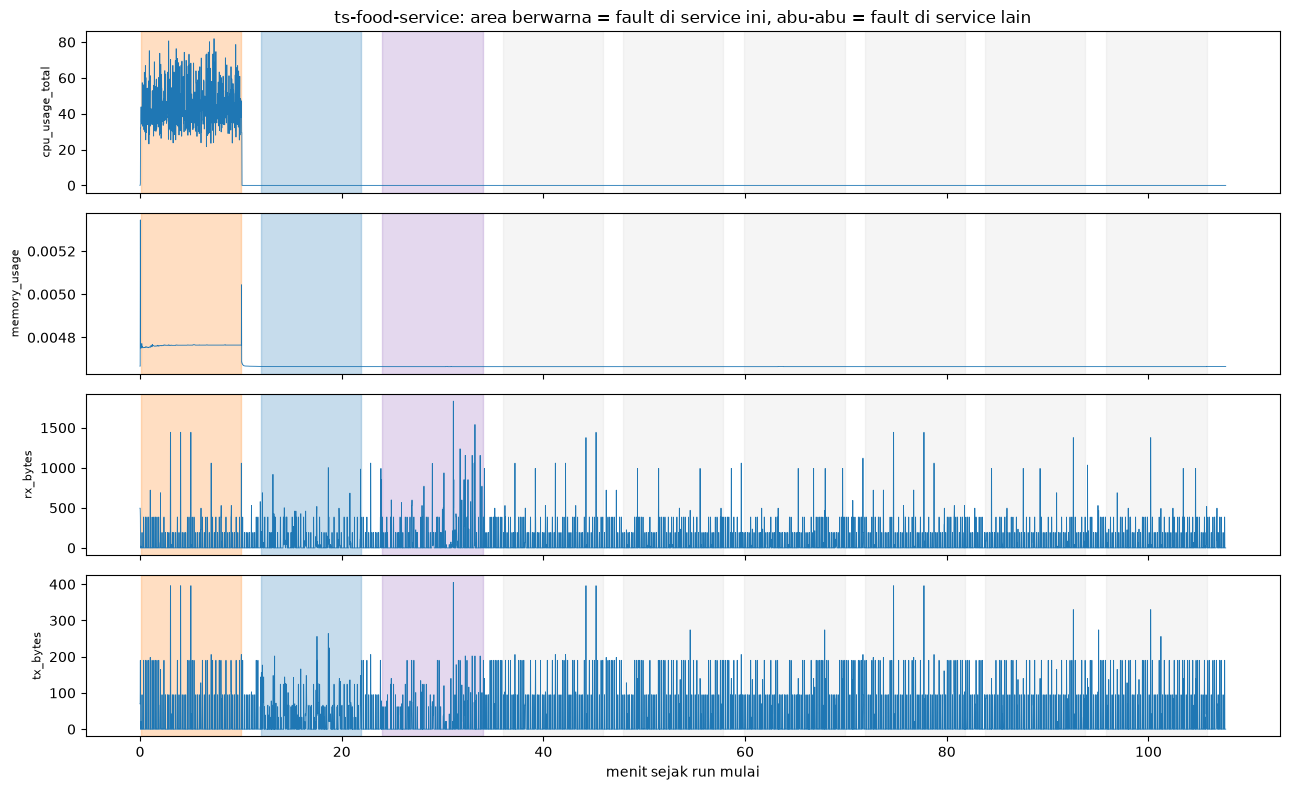

In [25]:
run_id = os.path.basename(RUN)[3:20]
fr = faults[faults.run == run_id]
t0 = fr.run_start.iloc[0]

SERVICE = "ts-food-service"     # coba ganti dengan service lain di run ini: ts-travel-service, ts-contacts-service
m = pd.read_csv(f"{RUN}/metrics/{SERVICE}.csv")
fig, axes = plt.subplots(4, 1, figsize=(13, 8), sharex=True)
for ax, col in zip(axes, ["cpu_usage_total", "memory_usage", "rx_bytes", "tx_bytes"]):
    ax.plot((m.timestamp - t0) / 60, m[col], lw=0.6)
    ax.set_ylabel(col, fontsize=8)
    for _, f in fr.iterrows():
        kena = f.service == SERVICE
        ax.axvspan((f.start - t0) / 60, (f.start + f.durasi - t0) / 60,
                   color=warna[f.fault] if kena else "grey", alpha=0.25 if kena else 0.08)
axes[0].set_title(f"{SERVICE}: area berwarna = fault di service ini, abu-abu = fault di service lain")
axes[-1].set_xlabel("menit sejak run mulai")
plt.tight_layout(); plt.show()